In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [3]:
img = cv2.imread('sample_image.jpg', cv2.IMREAD_GRAYSCALE)

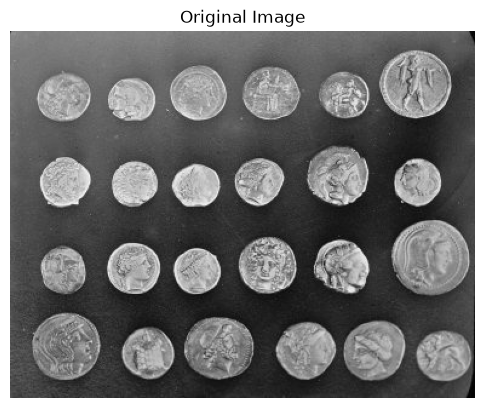

In [4]:
plt.figure(figsize=(6,5))
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')
plt.show()

## Threshold Segmentation

In [5]:
fixed_threshold = 127

In [8]:
# manual

global_thresh_manual = np.where(img >= fixed_threshold, 255, 0)
global_thresh_manual = global_thresh_manual.astype(np.uint8)

In [9]:
# auto

_, global_thresh_cv2 = cv2.threshold(img, fixed_threshold, 255, cv2.THRESH_BINARY)

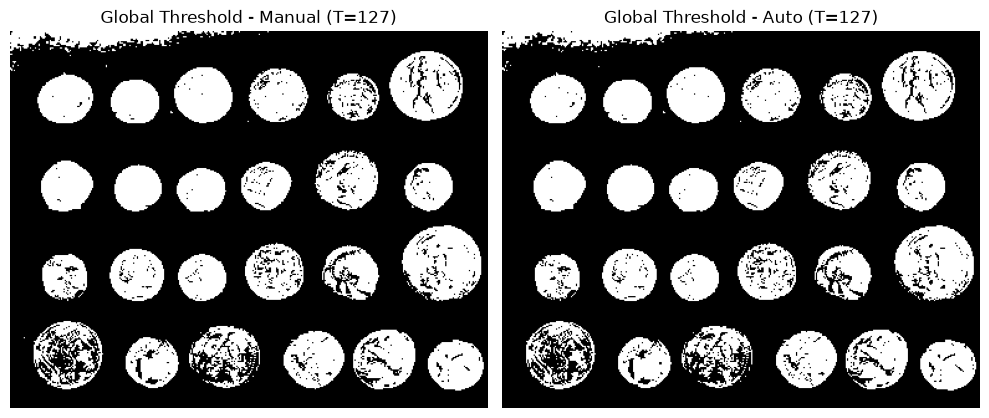

In [12]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(global_thresh_manual, cmap='gray')
plt.title(f"Global Threshold - Manual (T={fixed_threshold})")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(global_thresh_cv2, cmap='gray')
plt.title(f"Global Threshold - Auto (T={fixed_threshold})")
plt.axis('off')

plt.tight_layout()
plt.show()

In [13]:
# otsu method

otsu_value, otsu_thresh = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

print("\nOtsu automatically selected threshold value:", otsu_value)


Otsu automatically selected threshold value: 107.0


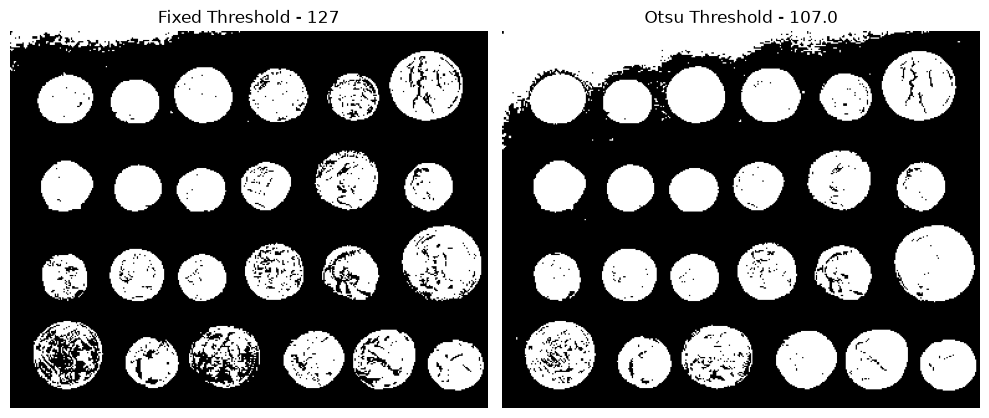

In [14]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(global_thresh_cv2, cmap='gray')
plt.title(f"Fixed Threshold - {fixed_threshold}")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(otsu_thresh, cmap='gray')
plt.title(f"Otsu Threshold - {otsu_value}")
plt.axis('off')

plt.tight_layout()
plt.show()

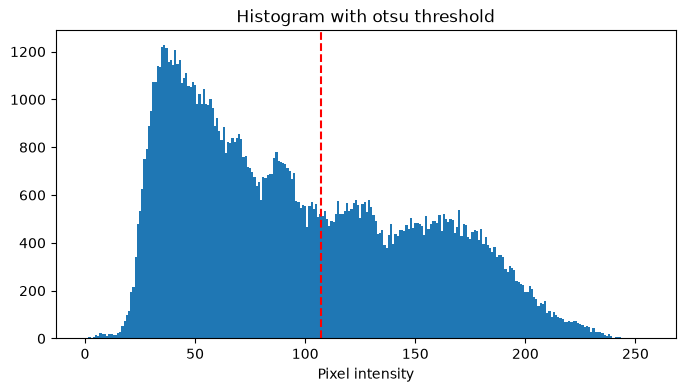

In [15]:
# Histogram with otsu threshold

hist, _ = np.histogram(img.flatten(), bins=256, range=(0,256))
plt.figure(figsize=(8,4))
plt.bar(range(256), hist, width=1)
plt.axvline(x=otsu_value, color='red', linestyle='--', label=f'Otsu threshold=')
plt.title('Histogram with otsu threshold')
plt.xlabel('Pixel intensity')
plt.show()

In [16]:
# adaptive thresholding

adaptive_mean = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, blockSize=11, C=2)

In [17]:
adaptive_gaussian = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, blockSize=11, C=2)

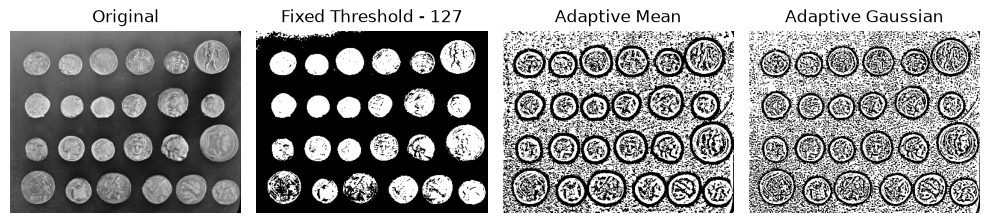

In [19]:
plt.figure(figsize=(10,5))

plt.subplot(1,4,1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis('off')

plt.subplot(1,4,2)
plt.imshow(global_thresh_cv2, cmap='gray')
plt.title(f"Fixed Threshold - {fixed_threshold}")
plt.axis('off')

plt.subplot(1,4,3)
plt.imshow(adaptive_mean, cmap='gray')
plt.title("Adaptive Mean")
plt.axis('off')

plt.subplot(1,4,4)
plt.imshow(adaptive_gaussian, cmap='gray')
plt.title("Adaptive Gaussian")
plt.axis('off')

plt.tight_layout()
plt.show()

In [20]:
# Simple region extraction

extracted_region = cv2.bitwise_and(img, img, mask=otsu_thresh)

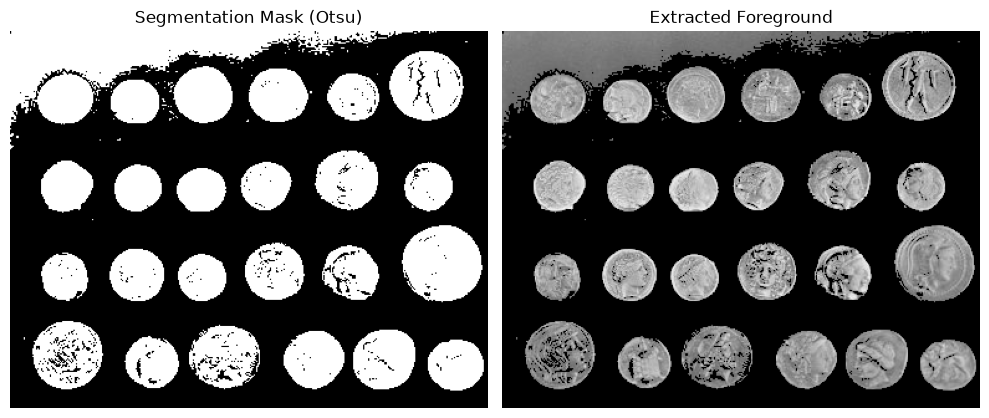

In [22]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(otsu_thresh, cmap='gray')
plt.title("Segmentation Mask (Otsu)")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(extracted_region, cmap='gray')
plt.title("Extracted Foreground")
plt.axis('off')

plt.tight_layout()
plt.show()

In [23]:
# Canny edge detection

canny_edges = cv2.Canny(img, threshold1=100, threshold2=200)

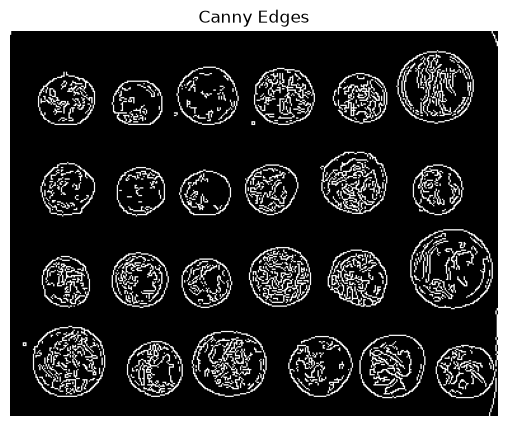

In [24]:
plt.figure(figsize=(10,5))
plt.imshow(canny_edges, cmap='gray')
plt.title("Canny Edges")
plt.axis('off')
plt.show()

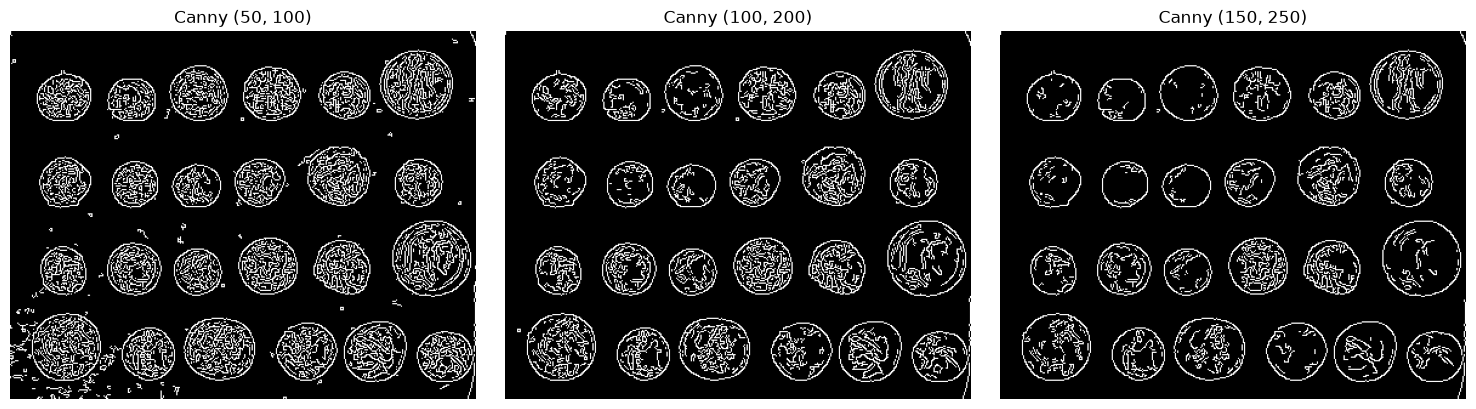

In [27]:
# Canny with different thresholdings

threshold_pairs = [(50,100), (100,200), (150,250)]
plt.figure(figsize=(15,4))

for i, (t1,t2) in enumerate(threshold_pairs):
    edges = cv2.Canny(img, t1, t2)
    plt.subplot(1, len(threshold_pairs), i+1)
    plt.imshow(edges, cmap='gray')
    plt.title(f"Canny ({t1}, {t2})")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [28]:
# Connected component

_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

In [29]:
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(binary)

In [31]:
print("Number of connected components found (including background) =",num_labels)
print("Number of actual objects (excluidng background) =",num_labels-1)

Number of connected components found (including background) = 95
Number of actual objects (excluidng background) = 94


In [33]:
# Colouring connected components

coloured_labels = np.zeros((*labels.shape,3), dtype=np.uint8)
rng = np.random.default_rng(42)
colours = rng.integers(0,255,size=(num_labels,3))
colours[0] = [0,0,0]

In [34]:
for label_id in range(num_labels):
    coloured_labels[labels == label_id] = colours[label_id]

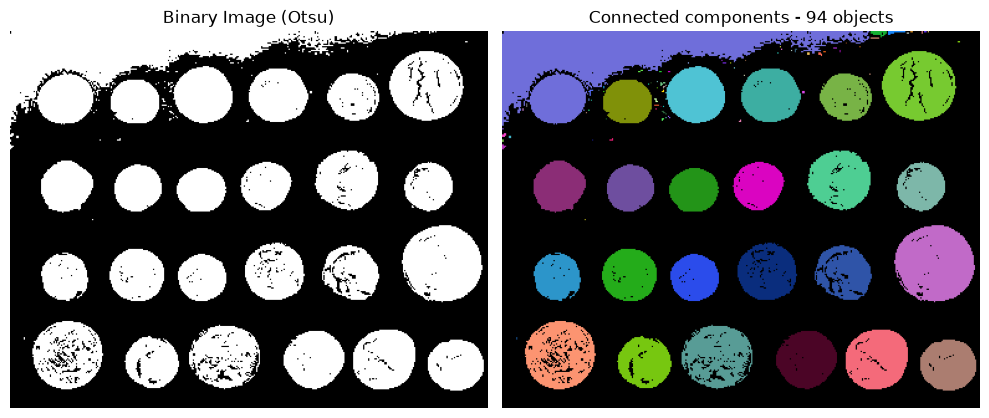

In [35]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(binary, cmap='gray')
plt.title("Binary Image (Otsu)")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(coloured_labels, cmap='gray')
plt.title(f"Connected components - {num_labels-1} objects")
plt.axis('off')

plt.tight_layout()
plt.show()